<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 First Stage Landing Prediction**


 ## Hands-on Lab: Complete the EDA with Visualization


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage. 

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans. 


  ## Objectives
Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

- Exploratory Data Analysis
- Preparing Data  Feature Engineering 


----


Install the below libraries


In [1]:
# Install only missing packages into this notebook's Python.
import importlib.util
import subprocess
import sys

missing = [name for name in ("pandas", "numpy", "seaborn", "matplotlib")
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab 



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter, StrMethodFormatter, MaxNLocator
from matplotlib.lines import Line2D
from pathlib import Path

LAB_DIR = Path("capstone") if Path("capstone").is_dir() else Path(".")
OUTPUT_DIR = LAB_DIR / "dataviz_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
OUTCOME_COLORS = {0: "#D55E00", 1: "#0072B2"}


def save_chart(fig, filename):
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def label_outcomes(legend):
    legend.set_title("Landing outcome")
    for text, label in zip(legend.get_texts(), ["0: Unsuccessful", "1: Successful"]):
        text.set_text(label)


def categorical_scatter(x, y, title, filename, xlabel, ylabel):
    # Horizontal strip plots keep x numeric, avoiding 90 crowded flight-number ticks.
    plot = sns.catplot(
        data=df, x=x, y=y, hue="Class", hue_order=[0, 1],
        kind="strip", orient="h", jitter=False,
        order=sorted(df[y].unique()), palette=OUTCOME_COLORS,
        height=5, aspect=2.1, size=6, alpha=0.85,
    )
    plot.set_axis_labels(xlabel, ylabel)
    plot.ax.set_title(title, loc="left", pad=16, fontweight="bold")
    plot.ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    plot.ax.xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))
    plot.ax.grid(axis="y", visible=False)
    plot.legend.remove()
    plot.figure.subplots_adjust(right=0.78)
    handles = [
        Line2D([], [], marker="o", linestyle="", color=OUTCOME_COLORS[value],
               markersize=7, label=label)
        for value, label in [(0, "0: Unsuccessful"), (1, "1: Successful")]
    ]
    plot.ax.legend(handles=handles, title="Landing outcome", loc="upper left",
                   bbox_to_anchor=(1.02, 1), frameon=False, borderaxespad=0)
    save_chart(plot.figure, filename)

/var/folders/kf/vykd4ky17jq2467hdrt_0hsm0000gn/T/ipykernel_5983/597843876.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Exploratory Data Analysis 


Read `dataset_part_2.csv`, produced by the data-wrangling notebook. Run all cells in order. This notebook uses local data, saves seven charts in `dataviz_outputs/`, and exports `dataset_part_3.csv` beside the notebook. Class 1 follows the lab's definition of a successful landing, including `True Ocean`; it does not mean every booster was recovered for reuse.

In [3]:
dataset_path = LAB_DIR / "dataset_part_2.csv"
if not dataset_path.is_file():
    raise FileNotFoundError(
        "Run labs-jupyter-spacex-Data wrangling-v2.ipynb first to create dataset_part_2.csv."
    )
df = pd.read_csv(dataset_path)
required_columns = {
    "FlightNumber", "Date", "PayloadMass", "Orbit", "LaunchSite", "Flights",
    "GridFins", "Reused", "Legs", "LandingPad", "Block", "ReusedCount", "Serial", "Class",
}
if required_columns - set(df.columns):
    raise ValueError(f"Missing columns: {sorted(required_columns - set(df.columns))}")
if df.empty or not df["Class"].isin([0, 1]).all():
    raise ValueError("Expected a nonempty dataset with binary Class labels.")
print(f"Loaded {len(df)} launches from {dataset_path}")
df.head(5)

Loaded 90 launches from dataset_part_2.csv


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6123.547647,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0.0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0.0,B1004,-80.577366,28.561857,0


First, plot flight number against payload mass and color each launch by landing outcome. Flight number describes chronological order in this dataset, not the number of flights of an individual booster. Later flights include more successful landings, but payload mass alone does not separate successful and unsuccessful outcomes. Payloads with unknown original mass were mean-imputed in the preceding lab.

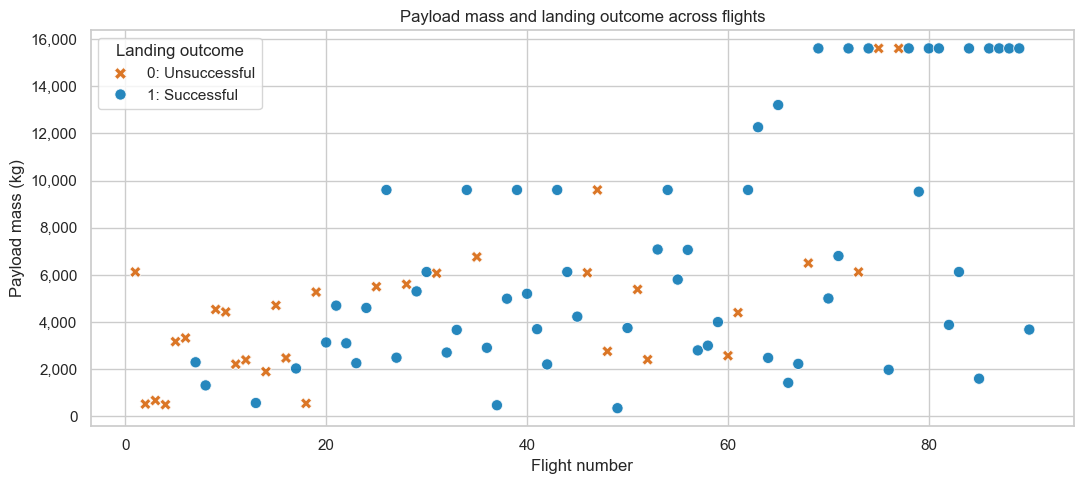

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(
    data=df, x="FlightNumber", y="PayloadMass", hue="Class", style="Class",
    hue_order=[0, 1], style_order=[0, 1], palette=OUTCOME_COLORS,
    markers={0: "X", 1: "o"}, s=65, alpha=0.85, ax=ax,
)
ax.set(title="Payload mass and landing outcome across flights",
       xlabel="Flight number", ylabel="Payload mass (kg)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
label_outcomes(ax.legend_)
fig.tight_layout()
save_chart(fig, "00_flight_number_vs_payload.png")

Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use `catplot` to plot `FlightNumber` on the x-axis, `LaunchSite` on the y-axis, and the case-sensitive column `Class` as the hue.

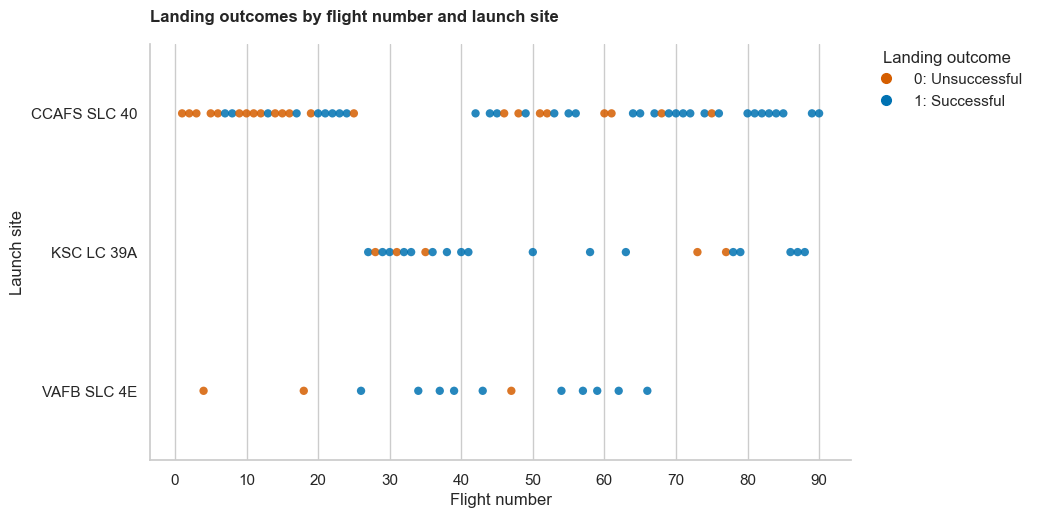

,Launches,Successes,SuccessRate
LaunchSite,,,
CCAFS SLC 40,55,33,0.600000
KSC LC 39A,22,17,0.772727
VAFB SLC 4E,13,10,0.769231


In [5]:
categorical_scatter(
    "FlightNumber", "LaunchSite", "Landing outcomes by flight number and launch site",
    "01_flight_number_vs_launch_site.png", "Flight number", "Launch site",
)
site_summary = df.groupby("LaunchSite")["Class"].agg(
    Launches="size", Successes="sum", SuccessRate="mean"
)
site_summary

**Observation:** CCAFS SLC 40 accounts for 55 launches with a 60.0% success rate; KSC LC 39A has 22 launches at 77.3%; VAFB SLC 4E has 13 at 76.9%. The plot shows more successes among later flights. The sites cover different time periods and missions, so these rates alone do not establish that one site causes better outcomes.

### TASK 2: Visualize the relationship between Payload and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


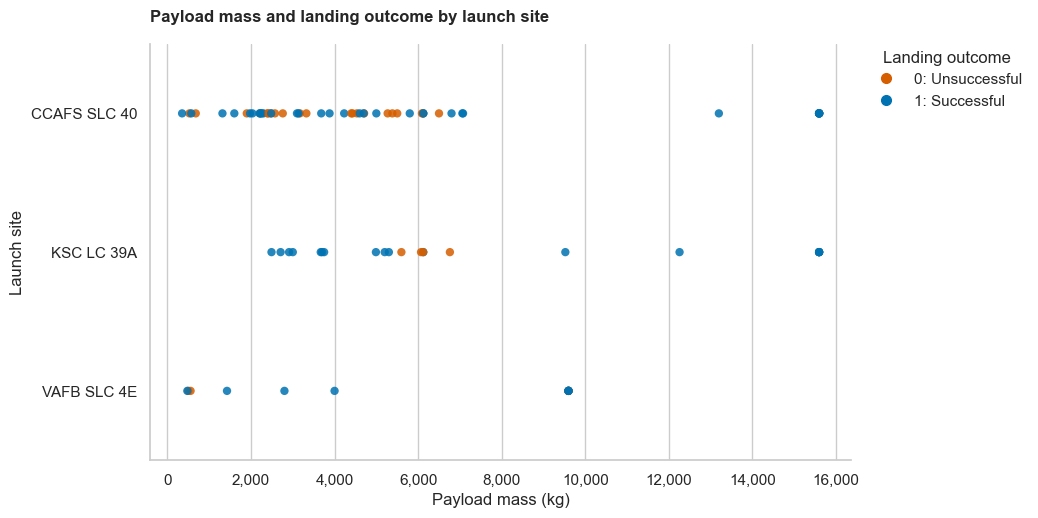

LaunchSite
CCAFS SLC 40    15600.0
KSC LC 39A      15600.0
VAFB SLC 4E      9600.0
Name: MaximumPayloadKG, dtype: float64

In [6]:
categorical_scatter(
    "PayloadMass", "LaunchSite", "Payload mass and landing outcome by launch site",
    "02_payload_vs_launch_site.png", "Payload mass (kg)", "Launch site",
)
df.groupby("LaunchSite")["PayloadMass"].max().rename("MaximumPayloadKG")

**Observation:** VAFB SLC 4E's largest payload is 9,600 kg in this dataset, so none exceeds 10,000 kg. Both CCAFS SLC 40 and KSC LC 39A include payloads up to 15,600 kg. Both outcome classes appear at overlapping masses; a mass threshold alone does not predict landing success.

### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


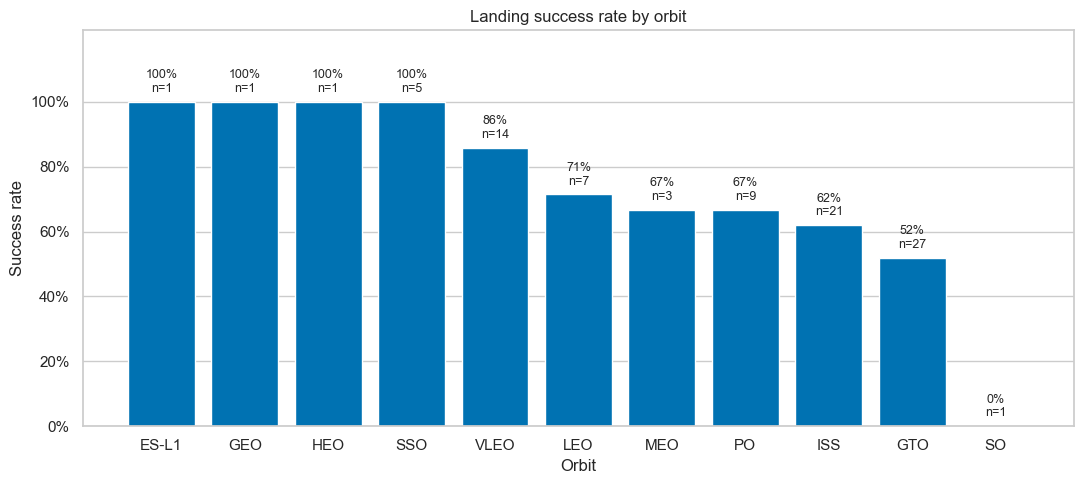

,SuccessRate,Launches
Orbit,,
ES-L1,1.000000,1
GEO,1.000000,1
HEO,1.000000,1
SSO,1.000000,5
VLEO,0.857143,14
LEO,0.714286,7
MEO,0.666667,3
PO,0.666667,9
ISS,0.619048,21


In [7]:
orbit_summary = (
    df.groupby("Orbit")["Class"]
      .agg(SuccessRate="mean", Launches="size")
      .sort_values("SuccessRate", ascending=False)
)
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(orbit_summary.index, orbit_summary["SuccessRate"], color="#0072B2")
for bar, (_, row) in zip(bars, orbit_summary.iterrows()):
    ax.annotate(
        f"{row['SuccessRate']:.0%}\nn={int(row['Launches'])}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", fontsize=9,
    )
ax.set(title="Landing success rate by orbit", xlabel="Orbit", ylabel="Success rate", ylim=(0, 1.22))
ax.set_yticks(np.linspace(0, 1, 6))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
fig.tight_layout()
save_chart(fig, "03_success_rate_by_orbit.png")
orbit_summary

**Observation:** ES-L1, GEO, HEO, and SSO each show 100% success. ES-L1, GEO, and HEO have only one launch each, while SSO has five, so those percentages have limited evidence. VLEO has 12 successes in 14 launches (85.7%). GTO has 14 successes in 27 launches (51.9%). The chart reports `n` to make the unequal sample sizes visible.

### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


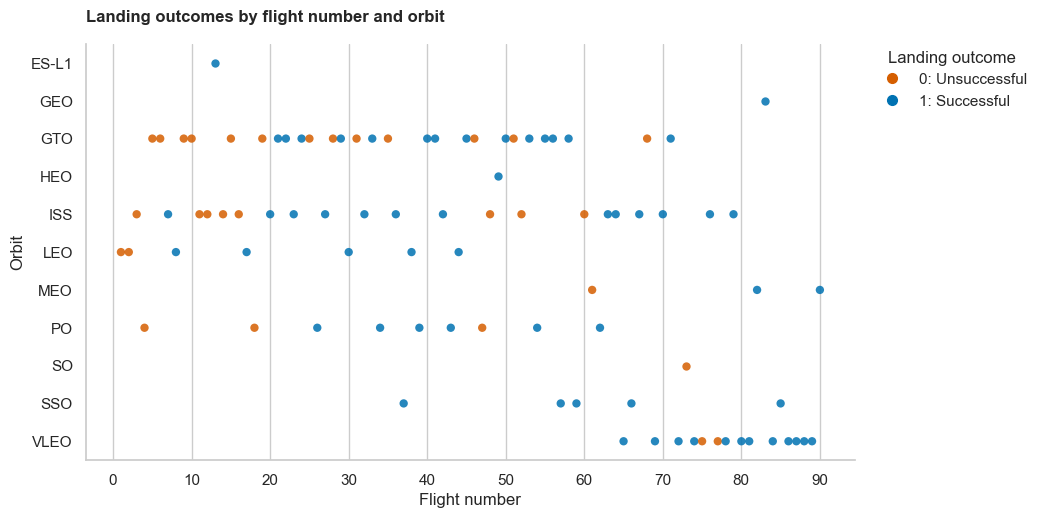

In [8]:
categorical_scatter(
    "FlightNumber", "Orbit", "Landing outcomes by flight number and orbit",
    "04_flight_number_vs_orbit.png", "Flight number", "Orbit",
)

**Observation:** LEO's earliest launches include unsuccessful landings, while its later observations are successful. GTO has both outcomes spread across flight numbers. Some orbit groups appear only late in the sequence, so orbit type and time are intertwined; this plot alone does not establish an independent flight-number effect.

### TASK  5: Visualize the relationship between Payload and Orbit type


Similarly, we can plot the Payload vs. Orbit scatter point charts to reveal the relationship between Payload and Orbit type


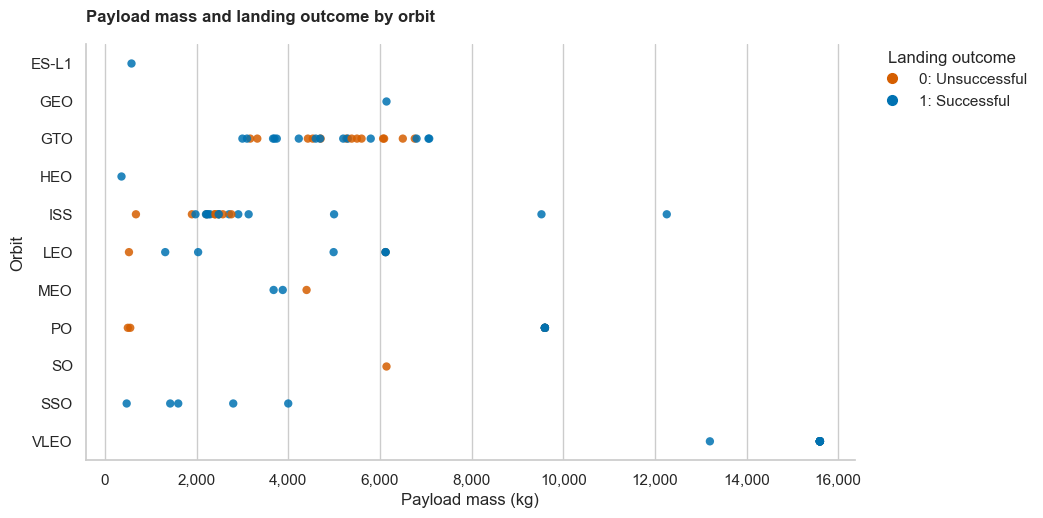

,Launches,SuccessRate
Orbit,,
ISS,1,1.000000
VLEO,14,0.857143


In [9]:
categorical_scatter(
    "PayloadMass", "Orbit", "Payload mass and landing outcome by orbit",
    "05_payload_vs_orbit.png", "Payload mass (kg)", "Orbit",
)
df.loc[df["PayloadMass"] > 10000].groupby("Orbit")["Class"].agg(
    Launches="size", SuccessRate="mean"
)

**Observation:** Payloads above 10,000 kg occur in ISS (one successful launch) and VLEO (12 successes in 14 launches) in this dataset. GTO contains both successes and failures at overlapping masses. These descriptive patterns are also affected by orbit, launch period, and the preceding payload-mass imputation.

### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend. 


The function will help you get the year from the date:


In [10]:
def Extract_year(date):
    """Extract years from the supplied date Series without retaining mutable state."""
    return pd.to_datetime(date, errors="raise").dt.year

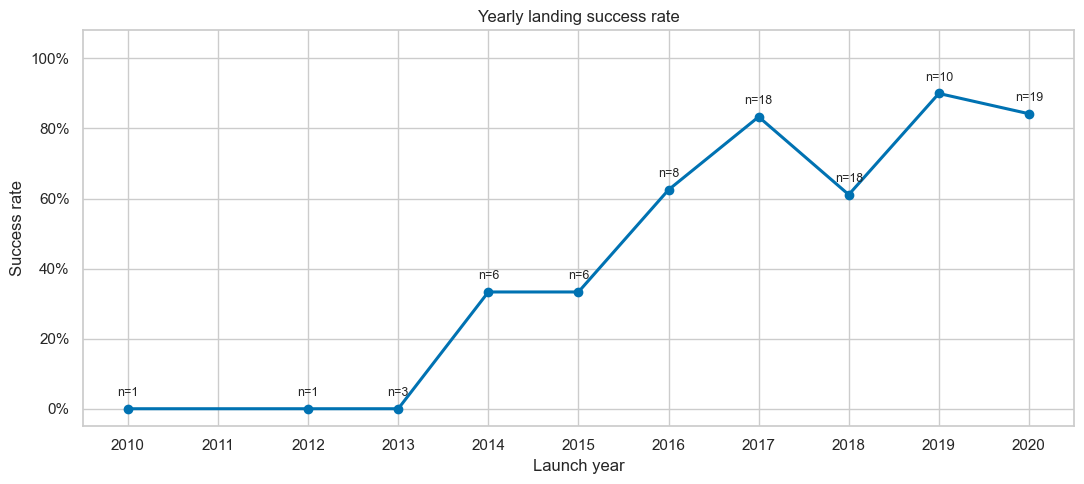

,SuccessRate,Launches
Year,,
2010,0.000000,1
2012,0.000000,1
2013,0.000000,3
2014,0.333333,6
2015,0.333333,6
2016,0.625000,8
2017,0.833333,18
2018,0.611111,18
2019,0.900000,10


In [11]:
df["Year"] = Extract_year(df["Date"])
yearly_summary = (
    df.groupby("Year")["Class"]
      .agg(SuccessRate="mean", Launches="size")
      .sort_index()
)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yearly_summary.index, yearly_summary["SuccessRate"], marker="o",
        linewidth=2.2, color="#0072B2")
for year, row in yearly_summary.iterrows():
    ax.annotate(f"n={int(row['Launches'])}", (year, row["SuccessRate"]),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Yearly landing success rate", xlabel="Launch year",
       ylabel="Success rate", ylim=(-0.05, 1.08))
ax.set_xticks(range(int(yearly_summary.index.min()), int(yearly_summary.index.max()) + 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
save_chart(fig, "06_yearly_success_rate.png")
yearly_summary

**Observation:** Success is 0% in the observed years 2010, 2012, and 2013; there are no 2011 records. It is 33.3% in both 2014 and 2015, rises to 83.3% in 2017, drops to 61.1% in 2018, and reaches 90.0% in 2019 and 84.2% in 2020. The long-term increase is not monotonic. The line connects observed years; it does not imply any observations in 2011.

## Features Engineering 


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the future module.


In [12]:
features = df[[
    "FlightNumber", "PayloadMass", "Orbit", "LaunchSite", "Flights", "GridFins",
    "Reused", "Legs", "LandingPad", "Block", "ReusedCount", "Serial",
]].copy()
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6123.547647,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0.0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0.0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0.0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0.0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0.0,B1004


 ### TASK  7: Create dummy variables to categorical columns


Use `pd.get_dummies()` on the actual column names `Orbit`, `LaunchSite`, `LandingPad`, and `Serial`. Keep the other selected features. Following the lab's default encoding, missing `LandingPad` values have zeros in all landing-pad indicators. Keep the target `Class` out of the feature matrix.

In [13]:
categorical_columns = ["Orbit", "LaunchSite", "LandingPad", "Serial"]
features_one_hot = pd.get_dummies(
    features, columns=categorical_columns, dtype=float, dummy_na=False
)
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6123.547647,1,False,False,False,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,525.000000,1,False,False,False,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,677.000000,1,False,False,False,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,500.000000,1,False,False,False,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,3170.000000,1,False,False,False,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers cast the entire dataframe to variable type <code>float64</code>


In [14]:
features_one_hot = features_one_hot.astype("float64")
assert "Class" not in features_one_hot.columns
assert features_one_hot.index.equals(df.index)
assert np.isfinite(features_one_hot.to_numpy()).all()
print(f"Feature matrix: {features_one_hot.shape[0]} rows x {features_one_hot.shape[1]} columns")
features_one_hot.dtypes

Feature matrix: 90 rows x 80 columns


FlightNumber    float64
PayloadMass     float64
Flights         float64
GridFins        float64
Reused          float64
                 ...   
Serial_B1056    float64
Serial_B1058    float64
Serial_B1059    float64
Serial_B1060    float64
Serial_B1062    float64
Length: 80, dtype: object

We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range. 


In [15]:
output_path = LAB_DIR / "dataset_part_3.csv"
features_one_hot.to_csv(output_path, index=False)
print(f"Saved {output_path}")
print(f"Saved seven charts to {OUTPUT_DIR}")

Saved dataset_part_3.csv
Saved seven charts to dataviz_outputs


## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


<a href="https://www.linkedin.com/in/nayefaboutayoun/">Nayef Abou Tayoun</a> is a Data Scientist at IBM and pursuing a Master of Management in Artificial intelligence degree at Queen's University.


## Change Log


| Date (YYYY-MM-DD) | Version | Changed By | Change Description      |
| ----------------- | ------- | ---------- | ----------------------- |
| 2021-10-12        | 1.1     | Lakshmi Holla     | Modified markdown |
| 2020-09-20        | 1.0     | Joseph     | Modified Multiple Areas |
| 2020-11-10       | 1.1    | Nayef      | updating the input data |


Copyright © 2020 IBM Corporation. All rights reserved.
